# Predizione della Bioattività di Molecole Prodotte dalle Piante

## Obiettivo
>Sviluppare modelli di machine learning per predire la **bioattività** di molecole prodotte dalle piante.

## Descrizione dataset
Il dataset è composto da 3 componenti:

### 1) "bioactivities" 
>Contiene l'elenco di bioattività tra molecole e proteine target. (source: [Papyrus](https://pmc.ncbi.nlm.nih.gov/articles/PMC9824924/))

- **Identificatori**
  - `Activity_ID` (*"primary key"*): identifica la **bioattività** di una coppia "molecola-proteina"
    - `InChIKey` (*"foreign key"*): identifica una specifica **molecola**
    - `target_id` (*"foreign key"*): identifica una specifica **proteina**

- **Statistiche bioattività**
  - `pchembl_value`: valori di bioattività derivanti da multiple misurazioni
    - 2 interpretazioni euristiche possibili:
      1) la più comune:
         - **Active**$~~~$: $\text{pChembl}  > 5.5$
         - **Inactive**: $\text{pChembl} <= 5.5$
      2) alternativa:
         - **Active**: $\text{pChembl} >= 6.0$
         - **Borderline**: $5.0 <= \text{pChembl} < 6.0$
         - **Inactive**: $\text{pChembl}  < 5.0$
  - `pchembl_value_Mean`: **media** dei valori di bioattività misurati
  - `pchembl_value_StdDev`: **deviazione standard** dei valori di bioattività misurati
  - `pchembl_value_SEM`: **errore standard della media** dei valori di bioattività misurati
  - `pchembl_value_N`: **numero** dei valori di bioattività misurati 
  - `pchembl_value_Median`: **mediana** dei valori di bioattività misurati
  - `pchembl_value_MAD`: **deviazione assoluta dalla mediana** dei valori di bioattività misurati

- **Metadati superflui**

	
### 2) "mass_spectra_embeddings"
>Contiene gli embedding delle molecole ottenuti con il tool python [Spec2Vec](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1008724) a partire dagli spettri di massa.

- **Identificatori**
  - `spectrum_id` (*"primary key"*): identifica uno specifico **spettro di una molecola**
    - `inchikey`: identifica una specifica **molecola**

- **Embedding features**
  - \[`0`,...,`499`\]: valori di embedding

- **Metadati superflui**

### 3) "protein_embeddings"
>Contiene 3 dimensionalità di embedding delle proteine ottenuti con UniRep. (source: [Papyrus](https://pmc.ncbi.nlm.nih.gov/articles/PMC9824924/))
1) File `protein_embeddings_UniRep64.csv`: embedding costituito da 3 componenti da 64 features/colonne, per un totale di 192 features
2) File `protein_embeddings_UniRep256.csv`: embedding costituito da 3 componenti da 256 features/colonne, per un totale di 768 features
3) File `protein_embeddings_UniRep1900.csv`: embedding costituito da 3 componenti da 1900 features/colonne, per un totale di 5700 features

- **Identificatori**
  - `target_id` (*"primary key"*): identifica una specifica **proteina**

- **Embedding features**
  - \[`UniRep64_AH_1`,...,`UniRep64_AH_64`,`UniRep64_FC_1`,...,`UniRep64_FC_64`,`UniRep64_FH_1`,...,`UniRep64_FH_64`\]: valori di embedding per ciascuna delle 3 componenti
  - \[`UniRep256_AH_1`,...,`UniRep256_AH_256`,`UniRep256_FC_256`,...
  - \[`UniRep1900_AH_1`,...,`UniRep1900_AH_1900`,`UniRep1900_FC_1900`,...


## Struttura del Notebook
1. Ipotesi e deduzioni
2. Configurazione ambiente ed import librerie
3. Caricamento dei dataset
4. Preprocessing
5. Training e validazione modelli
6. Conclusioni
---

# 1) Ipotesi e deduzioni
## Preliminari
### Composizione delle coppie per la misurazione della bioattività
Dato che i dataset di molecole e proteine contengono rispettivamente
- 5798 embedding di spettri di massa per 714 molecole distinte (circa 8 per molecola) e
- 1142 embedding di proteine distinte

avere 10092 "bioattività" per 714 molecole e 1142 proteine significa che
- ciascuna **proteina** è stata testata con circa 9 **molecole** ($10092/1142=8.83$) e
- ciascuna **molecola** è stata testata con circa 14 **proteine** ($10092/714=14.13$)

>Da ciò si evince che **si è cercato studiare il comportamento di "poche" molecole ma "a fondo"**.
___
### Scelta della dimensionalità dell'embedding delle proteine
Riguardo la presenza di **3 diverse dimensionalità** per gli embedding delle proteine (UniRep 64, 256 e 1900), è stato scelto di utilizzare la **dimensionalità maggiore** (UniRep 1900). 

>Questa decisione si basa sull'idea che sia **preferibile partire da una rappresentazione ricca di dettagli e sfumature strutturali** da cui estrarre l'essenza più informativa **tramite algoritmi di riduzione dimensionale**, piuttosto che **partire da embedding a bassa dimensionalità e lavorare su dati già compressi a monte**, con il rischio di aver perso irreversibilmente informazioni cruciali che nessuna tecnica successiva potrebbe recuperare.
___
### Obiettivo primario
Visto che l'obiettivo è costruire un classificatore che possa aiutare a identificare le molecole che hanno un "qualsiasi tipo di effetto" (bioattività) quando combinate con una proteina e che quindi vale la pena analizzare, la priorità è **evitare falsi negativi** perché i falsi positivi causeranno solo una piccola perdita di tempo in laboratorio.

>Per questo motivo si è scelto di affrontare il problema tramite **classificazione** piuttosto che **regressione**, in modo da ottimizzare direttamente il valore di ***Recall*** **privilegiando l'identificazione delle combinazioni attive** rispetto alla **minimizzazione dell'errore sulla stima puntuale del valore di bioattività**.

Inoltre, sono stati indicati 2 diversi criteri per classificare le bioattività e nessuna delle due dà origine a classi bilanciate infatti
- con soglia $5.5$:
  - 3651 `active`
  - 6441 `inactive`
- con soglie $5.0$ e $6.0$:
  - 2329 `active`
  - 6044 `borderline`
  - 1719 `inactive`

>Perciò è stato deciso di scegliere come unica soglia quella che **bilancia meglio le classi** cercando nell'intervallo compreso tra $5.0$ e $5.5$ inclusi: in questo modo c'è la possibilità di **bilanciare le classi** e al contempo di **sfavorire i falsi negativi** considerando come `active` anche alcuni valori che sarebbero stati `inactive` o `borderline`.

>Questo ha portato inoltre a scegliere la classificazione **binaria** rispetto a quella ternaria.
___
### Scelta del modello
Il modello di riferimento ha ottenuto buoni risultati
- combinando i 3 dataset **non aggregando gli embedding degli spettri delle molecole** e **scegliendo l'embedding delle proteine con più features**
- applicando **PCA separatamente a molecole e proteine** tenendo per entrambe lo **stesso numero di componenti** (32, 64, 128, 256, 500)
- classificando tramite il modello **XGBoost**

>Almeno inizialmente, si è optato per una *feature reduction* tramite
- **PCA** (applicata come nel modello di riferimento anche se non particolarmente indicata in ambito classificazione) e
- **LDA** (applicata post join dei dataset più adatta in ambito classificazione)

>e per l'utilizzo dei modelli
- **Random forest** (perfetto per la classificazione) e
- **XGBoost** (tecnica adoperata dal modello di riferimento e considerata spesso migliore di RandomForest)

>In particolare verranno confrontate le combinazioni
- **PCA + XGBoost** (modello di riferimento)
- **LDA + XGBoost**
- **PCA + Random forest**
- **LDA + Random forest**
___
### Scelta della tecnica di validazione
>Per quanto riguarda la validazione, si è scelto di adoperare `StratifiedGroupKFold`: questo perché permette di mantenere le **proporzioni originali (bilanciate) delle due classi in ciascun fold** al contempo **evitando (solo) uno dei due possibili fenomeni di *Data Leakage***.

Infatti, a causa della natura combinatoria dei campioni di bioattività, non è possibile impedire contemporaneamente che nel *test set* finiscano  molecole e proteine già presenti anche nel *train set*.

>Per questo motivo si è scelto inizialmente di **raggruppare per molecola** permettendo che nel *test set* finisca una proteina già presente nel *train set* **ma provata con un'altra molecola**. Questo per **verificare direttamente la capacità** dei modelli di **predire la bioattività di molecole completamente nuove**.
___
## Sperimentali
### Aggregazione degli spettri di massa
La natura degli embedding di molecole e proteine è differente:
- embedding **molecole**: derivati da **spettri di massa**, misure fisiche reali soggette a rumore ambientale, strumentale, umano
- embedding **proteine**: derivati dalla **sequenza di amminoacidi** di ogni proteina che è quindi **fissa**

>A fronte di ciò, dopo aver effettuato qualche tentativo con **aggregazione tramite media degli spettri di massa** in fase di join, è stato scelto invece di **non aggregarli** permettendo ai modelli di **generalizzare meglio includendo possibili fluttuazioni spettrali per una stessa molecola**.

Questa scelta ha portato alla necessità di sfruttare l'HPC di ateneo.
___


# 2) Configurazione ambiente ed import librerie

In [13]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Modelli
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# Metriche
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef
)

# Validazione
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone

# Altro
import gc
import os
from pathlib import Path

# Impostazione del random seed per riproducibilità
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 3) Caricamento dei dataset

In [14]:
# Creazione cartella per l'output
os.makedirs('results', exist_ok=True) 

BASE_PATH = Path('dataset_bioactivities')

# Caricamento bioactivities
print("📊 Caricamento bioactivities...")
df_bioactivities = pd.read_csv(BASE_PATH / 'bioactivities' / 'dataset_bioactivities_negative.csv')

# Caricamento molecule embeddings
print("📊 Caricamento mass_spectra_embeddings...")
df_molecules = pd.read_csv(BASE_PATH / 'mass_spectra_embeddings' / 'ALL_GNPS_negative_ionization_DATASET.csv')

# Caricamento protein embeddings
print("📊 Caricamento protein_embeddings...")
df_proteins_1900 = pd.read_csv(BASE_PATH / 'protein_embeddings' / 'protein_embeddings_UniRep1900.csv')

print(f"\n✅ Dataset caricati con successo!")
print(f"   - Bioactivities: {df_bioactivities.shape}")
print(f"   - Molecules: {df_molecules.shape}")
print(f"   - Proteins (UniRep1900): {df_proteins_1900.shape}")

📊 Caricamento bioactivities...
📊 Caricamento mass_spectra_embeddings...
📊 Caricamento protein_embeddings...

✅ Dataset caricati con successo!
   - Bioactivities: (10092, 36)
   - Molecules: (5798, 507)
   - Proteins (UniRep1900): (1142, 5701)


# 4) Preprocessing

## Data cleaning
Osservando i dataset si può notare come i dati siano già di qualità, infatti
- non ci sono dati mancanti (a parte nei metadati superflui)
- nel dataset delle **bioattività** 
  - il dominio della feature `Quality` contiene solo la qualità "**High**"
  - il dominio della feature `Status` contiene solo il valore **reviewed**
    - ogni misurazione è stata controllata manualmente
- nel dataset delle **molecole**, il dominio della feature `ms_level` contiene solo il valore $2$
  - gli embedding sono ricchi di informazione perché comprendono le singole componenti della molecola invece che solo la molecola intera (`ms_level` $= 1$)

## Feature selection

>Rimozione **metadati superflui** e **statistiche di bioattività** superflue.

In [18]:
# Come statistica di bioattività si prende come riferimento pchembl_value_Mean
df_bioactivities.drop(columns=[
    'Quality', 'source', 'CID', 'SMILES', 'connectivity', 'InChI', 'InChI_AuxInfo', 'accession',
    'Protein_Type', 'AID', 'doc_id', 'Year', 'all_doc_ids', 'all_years', 'type_IC50', 'type_EC50',
    'type_KD', 'type_Ki', 'relation', 'HGNC_symbol', 'UniProtID', 'Status', 'Organism', 'Classification',
    'Length', 'Sequence',
    'pchembl_value', 'pchembl_value_StdDev', 'pchembl_value_SEM',
    'pchembl_value_N', 'pchembl_value_Median', 'pchembl_value_MAD'    
], inplace=True)

df_molecules.drop(columns=[
    'backbone_inchikey', 'spectrum_id', 'smiles', 'inchi', 'instrument', 'ms_level'
], inplace=True)

## Data preparation

>Si cerca la soglia che meglio bilancia le classi.

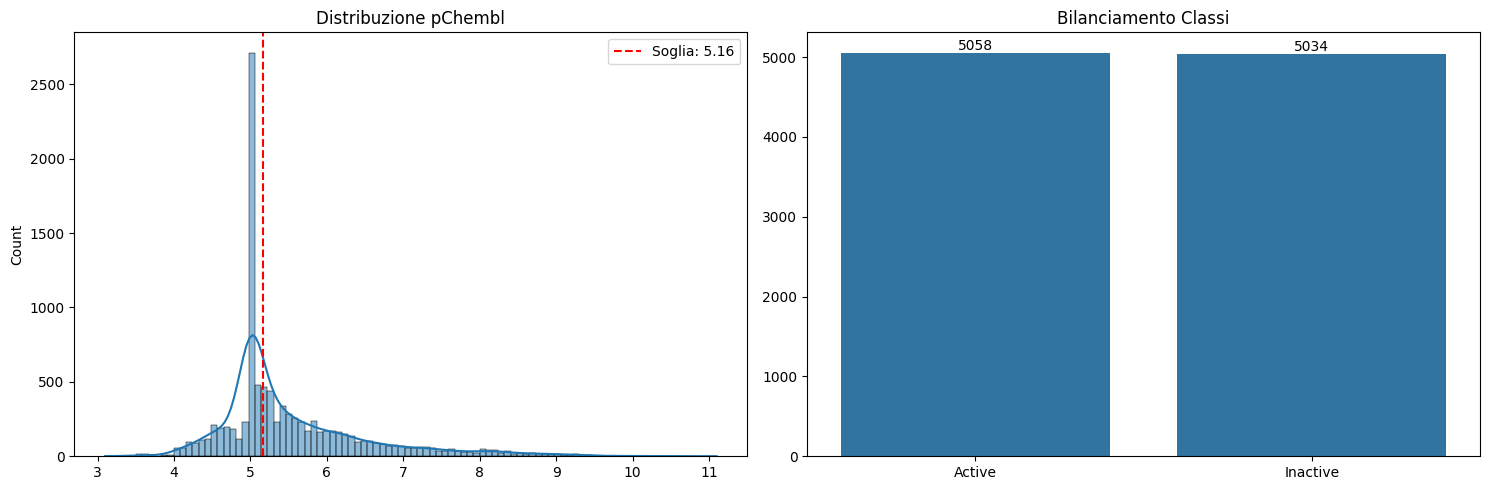

In [19]:
# Si ricerca nel range "safe" delle soglie (5.00-5.50)
pchembl_values = np.array(df_bioactivities['pchembl_value_Mean'].values)
thresholds = np.arange(5.00, 5.51, 0.01)

# Si contano gli attivi per ogni soglia (e gli inattivi per differenza)
active_counts = np.array([(pchembl_values >= t).sum() for t in thresholds])
inactive_counts = len(pchembl_values) - active_counts

# Si individua la soglia che minimizza la differenza tra le classi
best_idx = np.argmin(np.abs(active_counts - inactive_counts))
best_balancing_threshold = thresholds[best_idx]

# Recupero i conteggi finali
n_active = active_counts[best_idx]
n_inactive = inactive_counts[best_idx]

# Creazione Grafico
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# 1. Distribuzione e Soglia (Sinistra)
sns.histplot(pchembl_values, kde=True, ax=ax[0])
ax[0].axvline(best_balancing_threshold, color='red', linestyle='--', label=f'Soglia: {best_balancing_threshold:.2f}')
ax[0].set_title('Distribuzione pChembl')
ax[0].legend()

# 2. Bilanciamento Classi (Destra)
sns.barplot(x=['Active', 'Inactive'], y=[n_active, n_inactive], ax=ax[1])
ax[1].set_title('Bilanciamento Classi')
ax[1].bar_label(ax[1].containers[0]) # Aggiunge i numeri sopra le barre automaticamente

plt.tight_layout()
plt.show()

>Viene aggiunta la colonna indicante la classe per ogni bioattività secondo la soglia trovata.

In [20]:
df_bioactivities['bioactivity_class'] = np.where(
    df_bioactivities['pchembl_value_Mean'] >= best_balancing_threshold,
    'active',
    'inactive'
)

>Si effettua il merge tra i data set **verificando che le classi rimangano bilanciate** anche dopo l'aumento di record dovuto alla presenza di più spettri per singola molecola.


✅ Dataset merged:
df_merged: (106055, 6205)



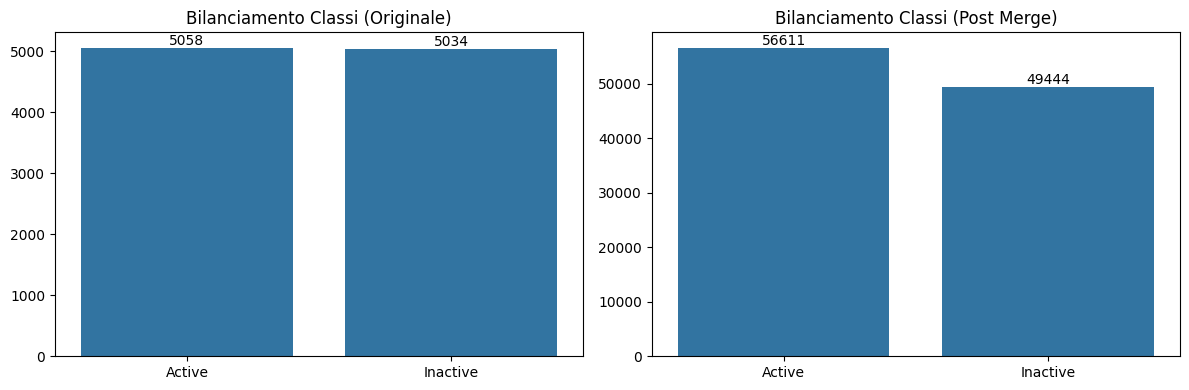

In [21]:
# Si rinomina la colonna InChIKey per uniformarla
df_bioactivities.rename(columns={'InChIKey': 'inchikey'}, inplace=True)

# Merge tra dataset bioattività e spettri molecole
df_merged = df_bioactivities.merge(df_molecules, on='inchikey', how='inner')

# Merge tra bioattività e spettri molecole con embedding proteine
df_merged = df_merged.merge(df_proteins_1900, on='target_id', how='inner')

print(f"\n✅ Dataset merged:")
print(f"df_merged: {df_merged.shape}\n")

# Conteggi classi originali e dopo merge
orig_counts = df_bioactivities['bioactivity_class'].value_counts()
merged_counts = df_merged['bioactivity_class'].value_counts()

# Barplot confronto bilanciamento classi
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=['Active', 'Inactive'], y=[orig_counts.get('active', 0), orig_counts.get('inactive', 0)], ax=ax[0])
ax[0].set_title('Bilanciamento Classi (Originale)')
ax[0].bar_label(ax[0].containers[0])

sns.barplot(x=['Active', 'Inactive'], y=[merged_counts.get('active', 0), merged_counts.get('inactive', 0)], ax=ax[1])
ax[1].set_title('Bilanciamento Classi (Post Merge)')
ax[1].bar_label(ax[1].containers[0])

plt.tight_layout()
plt.show()

>A questo punto, per il k-folding, si è scelto di effettuare un raggruppamento **per proteina** invece che per molecola perchè, nel dataset delle bioattività, **alcune proteine comparivano solo come `active` o solo come `inactive`** e ci sarebbe stato il rischio che il modello imparasse **solamente** la coppia "proteina-bioattività".

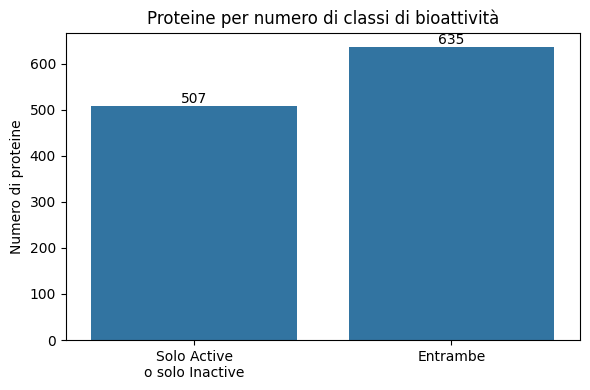

In [22]:
# Per ogni proteina, si conta quante classi distinte ha
classes_per_protein = df_bioactivities.groupby('target_id')['bioactivity_class'].nunique()

counts = classes_per_protein.value_counts().sort_index()
labels = {1: 'Solo Active\no solo Inactive', 2: 'Entrambe'}

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=[labels[k] for k in counts.index], y=counts.values, ax=ax)
ax.set_title('Proteine per numero di classi di bioattività')
ax.set_ylabel('Numero di proteine')
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

# 5) Training e Validazione

Si configura così una **Cross-Validation con k=5 fold** usando `StratifiedGroupKFold` per:
1. **Stratificare**: mantenere la distribuzione di `active`/`inactive` in ogni fold
2. **Raggruppare per proteina**: in questo modo si evita che il modello impari la coppia proteina-bioattività

> **Nota**: **Standardizzazione** e **Riduzione Dimensionalità** vengono applicate **dentro il loop di Cross-Validation** (`fit` su *train*, `transform` su train e test) per evitare *Data Leakage*.

In [23]:
# Identificazione colonne non-feature
non_feature_cols = ['Activity_ID', 'inchikey', 'target_id', 'pchembl_value_Mean', 'bioactivity_class']

# Identificazione colonne feature
feature_cols = [c for c in df_merged.columns if c not in non_feature_cols]

# Identificazione indici delle colonne molecola (numeriche: '0'-'499') e proteina (UniRep*)
mol_idx = [i for i, c in enumerate(feature_cols) if c.isdigit()]
prot_idx = [i for i, c in enumerate(feature_cols) if c.startswith('UniRep')]

# Preparazione dati per la CV
X = df_merged[feature_cols].values
y = df_merged['bioactivity_class'].values
groups = df_merged['target_id'].values

# Liberazione memoria: DataFrame originali non più necessari
del df_bioactivities, df_molecules, df_proteins_1900, df_merged
gc.collect()

# Configurazione CV
N_SPLITS = 5
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

>Da questo punto in poi, il codice contiene l'implementazione della migliore combinazione trovata di **tecniche di riduzione della dimensionalità** e **modelli di classificazione** con relativi **iperparametri** basandosi principalmente su *Recall* e *MCC*.

Tuttavia, per arrivare a tali configurazioni, sono state testate:
- tecniche di **riduzione della dimensionalità**:
  - **PCA**
    - a 32, 64, 128, 256, 500 componenti
    - a 600, 700, 800, 900, 1000 componenti per XGBoost
  - **LDA**
    - applicata per forza di cose all'intero dataset post merge
  - **UMAP supervised** (considera anche la classe durante la deformazione del manifold)
    - a 10 e 32 componenti
- modelli **classificatori**
  - **RandomForest**
  - **XGBoost**
  - **SVM** (bagged) 

>Le combinazioni migliori sono risultate essere **PCA+RandomForest** e **PCA+XGBoost**. Nelle Conclusioni i grafici comparatori.

**Modelli**: `XGBoost`, `RandomForestClassifier` (con **iperparametri** "best guess" per la *Recall*)

**Riduzione dimensionalità**: `PCA` a numero fisso di componenti (**32** e **256**)

In [ ]:
# Mappatura classi: active=1, inactive=0
y_enc = np.where(y == 'active', 1, 0)

# CPU assegnate (fallback a 8)
n_jobs = int(os.environ.get('SLURM_CPUS_PER_TASK', 8))

# Configurazioni PCA da testare
PCA_N_COMPONENTS = [32, 256]

# Definizione modelli
models = {
    # Parallel Ensemble: media di alberi profondi
    'RandomForest': RandomForestClassifier(
        n_estimators=500,   # tanti alberi per stabilizzare la predizione
        max_depth=None,     # massima capacità di catturare pattern complessi 
        random_state=RANDOM_STATE,
        n_jobs=n_jobs
    ),
    # Sequential Boosting: costruzione di alberi in sequenza per correggere gli errori dei precedenti
    'XGBoost': xgb.XGBClassifier(
        n_estimators=500,      # tanti di cicli di boosting/alberi per convergere 
        learning_rate=0.05,    # lento apprendimento per evitare oevrfitting
        max_depth=10,          # alta capacità di catturare pattern complessi 
        eval_metric='logloss', # calcolo errore su probabilità (soft) anzichè 0/1 (hard)
        random_state=RANDOM_STATE,
        device='cuda',
        n_jobs=n_jobs
    )
}

all_results = {}

def evaluate_fold(X_train, X_test, y_train, y_test, model, key):
    """Dato un fold, addestra un modello sul train set e lo valuta sul test set."""
    # Clona il modello base (così ogni fold parte da zero)
    clf = clone(model)

    print(f"   ⚙️ Training {key}...", end=" ", flush=True)
    clf.fit(X_train, y_train)
    print("✅", flush=True)

    # XGBoost su GPU: si sposta su CPU per la predizione per evitare warning
    if hasattr(clf, 'device') and clf.device == 'cuda':
        clf.set_params(device='cpu')

    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]

    # Calcolo metriche (classe positiva: active=1)
    metrics = {
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, pos_label=1),
        'Recall':    recall_score(y_test, y_pred, pos_label=1),
        'F1-score':  f1_score(y_test, y_pred, pos_label=1),
        'AUC':       roc_auc_score(y_test, y_proba),
        'MCC':       matthews_corrcoef(y_test, y_pred)
    }

    # Se il modello non esiste nel dizionario, crea un dizionario vuoto per lui
    if key not in all_results:
        all_results[key] = {}

    # Salvataggio nei rispettivi elenchi
    for metric_name, value in metrics.items():
        # Append a lista nuova o esistente per la key
        all_results[key].setdefault(metric_name, []).append(value)

def apply_pca_separated(X_train, X_test, n_comp):
    """Applica StandardScaler + PCA separatamente su molecole e proteine, poi scala il risultato."""
    parts_train, parts_test = [], []
    for idx in [mol_idx, prot_idx]:
        scaler = StandardScaler()
        pca = PCA(n_components=n_comp, random_state=RANDOM_STATE)
        parts_train.append(pca.fit_transform(scaler.fit_transform(X_train[:, idx])))
        parts_test.append(pca.transform(scaler.transform(X_test[:, idx])))

    scaler_final = StandardScaler()
    return scaler_final.fit_transform(np.hstack(parts_train)), \
           scaler_final.transform(np.hstack(parts_test))


# Lista per salvare le statistiche
fold_stats = []
for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X, y_enc, groups)):
    print(f"\n🔄 Fold {fold_idx+1}/{N_SPLITS}")
    X_train, X_test_raw = X[train_idx], X[test_idx]
    y_train, y_test = y_enc[train_idx], y_enc[test_idx]

    fold_stats.append((fold_idx+1, len(train_idx), len(test_idx),
                        y_train.mean()*100, y_test.mean()*100))

    for n_comp in PCA_N_COMPONENTS:
        print(f" > PCA({n_comp})...", flush=True)
        X_train_red, X_test_red = apply_pca_separated(X_train, X_test_raw, n_comp)
        for model_name, model in models.items():
            evaluate_fold(X_train_red, X_test_red, y_train, y_test, model, f'PCA({n_comp})_{model_name}')

# Liberazione memoria: array numpy non più necessari
del X, y, y_enc, groups
gc.collect()

# Tabella risultati finale
results_summary = []
for key, metrics in all_results.items():
    # Parsing chiave: 'PCA(256)_XGBoost' → ('PCA(256)', 'XGBoost')
    parts = key.split('_', 1)
    reduction = parts[0]
    model_part = parts[1]
    results_summary.append({
        'Reduction': reduction,
        'Model': model_part,
        'Accuracy': f"{np.mean(metrics['Accuracy']):.3f}±{np.std(metrics['Accuracy']):.3f}",
        'Precision': f"{np.mean(metrics['Precision']):.3f}±{np.std(metrics['Precision']):.3f}",
        'Recall': f"{np.mean(metrics['Recall']):.3f}±{np.std(metrics['Recall']):.3f}",
        'F1-score': f"{np.mean(metrics['F1-score']):.3f}±{np.std(metrics['F1-score']):.3f}",
        'AUC': f"{np.mean(metrics['AUC']):.3f}±{np.std(metrics['AUC']):.3f}",
        'MCC': f"{np.mean(metrics['MCC']):.3f}±{np.std(metrics['MCC']):.3f}",
        '_recall': np.mean(metrics['Recall'])
    })

df_results = pd.DataFrame(results_summary).sort_values('_recall', ascending=False).drop(columns=['_recall'])
df_results.to_csv('results/best_models.csv', index=False)

# Stampa della tabella dei fold
print("\n" + "="*80)
print("DISTRIBUZIONE NEI FOLD (Training Recap)")
print("="*80)
print(f"{'Fold':^5} | {'Train Size':^10} | {'Test Size':^10} | {'Train Active %':^15} | {'Test Active %':^15}")
print("-" * 75)
for row in fold_stats:
    print(f"{row[0]:^5} | {row[1]:^10} | {row[2]:^10} | {row[3]:^15.2f}% | {row[4]:^15.2f}%")
print("-" * 75)

Output da HPC:
```
===========================================================================
              DISTRIBUZIONE NEI FOLD (Training Recap)                      
===========================================================================
Fold  | Train Size |  Test Size  | Train Active %  |  Test Active %        
---------------------------------------------------------------------------
  1   |   83880    |   22175    |      53.07     % |      54.53     %      
  2   |   83338    |   22717    |      53.89     % |      51.49     %      
  3   |   83374    |   22681    |      53.44     % |      53.17     %      
  4   |   86450    |   19605    |      53.28     % |      53.81     %      
  5   |   87178    |   18877    |      53.22     % |      54.10     %      
---------------------------------------------------------------------------
```

# 6) Conclusioni

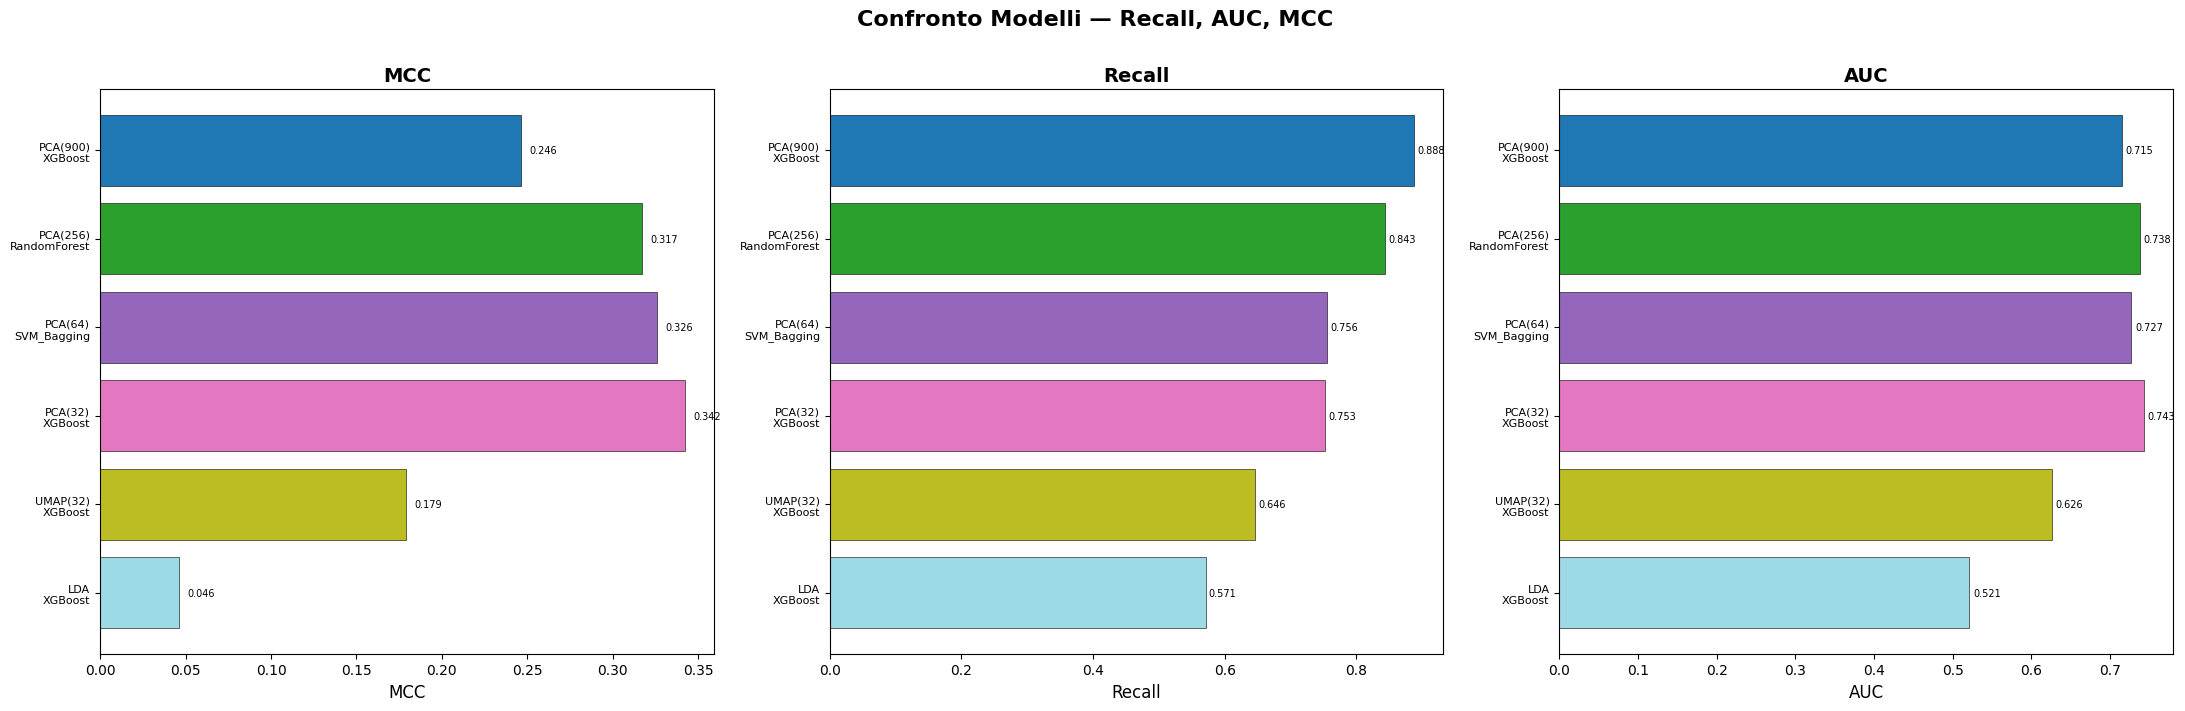

In [24]:
# --- Caricamento risultati ---
df_all = pd.read_csv('results/selection.csv')

# --- Parsing metriche (formato "mean±std") ---
def parse_metric(col):
    mean = col.str.split('±').str[0].astype(float)
    return mean

# Etichetta compatta per ogni configurazione
df_all['Label'] = df_all['Reduction'] + '\n' + df_all['Model']

metrics = ['MCC', 'Recall', 'AUC']
fig, axes = plt.subplots(1, 3, figsize=(22, 7), sharey=False)

# Ordina per Recall decrescente
recall_mean = parse_metric(df_all['Recall'])
order = recall_mean.sort_values(ascending=False).index
df_all = df_all.loc[order].reset_index(drop=True)

colors = plt.cm.tab20(np.linspace(0, 1, len(df_all)))

for ax, metric in zip(axes, metrics):
    mean = parse_metric(df_all[metric])
    bars = ax.barh(range(len(df_all)), mean, color=colors,
                   edgecolor='black', linewidth=0.4)
    ax.set_yticks(range(len(df_all)))
    ax.set_yticklabels(df_all['Label'], fontsize=8)
    ax.set_xlabel(metric, fontsize=12)
    ax.set_title(metric, fontsize=14, fontweight='bold')
    ax.invert_yaxis()
    # Aggiunge valori sulle barre
    for i, m in enumerate(mean):
        ax.text(m + 0.005, i, f'{m:.3f}', va='center', fontsize=7)

fig.suptitle('Confronto Modelli — Recall, AUC, MCC', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Questi grafici mostrano le metriche prese in considerazione per la scelta dei modelli migliori per l'obiettivo in questione:
- `MCC`: **metrica migliore per la classificazione binaria** in quanto produce buoni valori ($>0.3$) solo se la predizione ottiene buoni risultati in tutte e quattro le categorie della matrice di confusione, senza risentire dell'eventuale sbilanciamento delle classi 
- `Recall`: indica direttamente la **tendenza del modello a evitare falsi negativi**
- `AUC`: indica la probabilità che il modello assegni una probabilità più alta di positività a un'istanza casuale positiva rispetto ad un'istanza casuale negativa

>Tra tutte le combinazioni testate, oltre qualche eccezione rappresentativa, sono state selezionate quelle con un $\text{MCC} >0.3$ per porre un freno al valore massimo di `Recall` accettabile.

Infatti possiamo notare come:
- i migliori test con `UMAP` e `LDA` **non raggiungano la "soglia minima di bontà generale" MCC**
  - `LDA` -> nonostante **massimizzi la separabilità lineare**, è vincolata a ridurre le feature a $\text{n° classi}-1$ componenti e perciò, **ridurre una complessità biologica così elevata a una singola dimensione ha probabilmente causato una perdita di sfumature necessarie** per la generalizzazione su nuove proteine, risultando in un modello troppo semplicistico (*underfitting*)
  - `UMAP supervised` -> utilizzando le etichette per guidare la riduzione dimensionale, l'algoritmo ha **probabilmente "forzato" la creazione di cluster puri nel manifold di training**, imparando relazioni specifiche per le proteine note ma che non esistevano o erano diverse per le proteine mai viste nel test set, impattando sulla capacità di generalizzare
- la **migliore combinazione di `PCA` e `XGBoost` in quanto a Recall** ha un **MCC non accettabile**
  - probabile overfitting

Inoltre
- il miglior test con `SVM` (non lineare) **supera la soglia MCC** ma
  - è stato scartato a causa delle relativamente **scarse prestazioni in termini di *Recall*** (anche dopo forti riduzioni di dimensionalità con PCA) e a causa della **scarsa scalabilità rispetto alla numerosità del dataset** (è stata adoperata una tecnica di Bagging per rendere il calcolo fattibile in tempi ragionevoli)
- la combinazione **più equilibrata** risulta essere quella con **PCA a 32 componenti e XGBoost** (migliori valori MCC e AUC) 
  - tuttavia ha **Recall** **lontana dalla migliore** 
___
>Da ciò, risulta evidente come il miglior modello per la Recall e quindi per l'obiettivo primario del progetto risulta essere quello che prevede **PCA a 256 componenti e RandomForest**.  
___
Infatti esso ha 
- `MCC` **sopra la soglia minima**
- `Recall` **molto alta**
- `AUC` **seconda solo al modello più bilanciato**

Inoltre
- `F1-score` **più alto di qualsiasi altro test** ad indicare l'**efficacia contemporanea in termini di precisione e robustezza**
  - pochi **falsi positivi** e pochi **falsi negativi**
    - probabilmente grazie al *Feature Bagging*
___
Per completezza, la tabella con tutti gli indici calcolati:

| Reduction | Model | Accuracy | Precision | Recall | F1-score | AUC | MCC |
|-----------|-------|----------|-----------|--------|----------|-----|-----|
| PCA(900) | XGBoost | 0.621 | 0.599 | **0.888** | 0.715 | 0.715 | 0.246 |
| `PCA(256)` | `RandomForest` | `0.656` | `0.635` | `0.843` | **`0.724`** | `0.738` | `0.317` |
| PCA(64) | SVM_Bagging | 0.666 | 0.665 | 0.756 | 0.707 | 0.727 | 0.326 |
| PCA(32) | XGBoost | **0.674** | **0.675** | 0.753 | 0.712 | **0.743** | **0.342** |
| LDA | XGBoost | 0.525 | 0.560 | 0.571 | 0.558 | 0.521 | 0.046 |
| UMAP(32) | XGBoost | 0.592 | 0.613 | 0.646 | 0.628 | 0.626 | 0.179 |